# Build the data for a chest X-ray report assistant
**RSNA 2026 · Lab 08 · Main notebook · 45-minute guided pathway · CPU only**

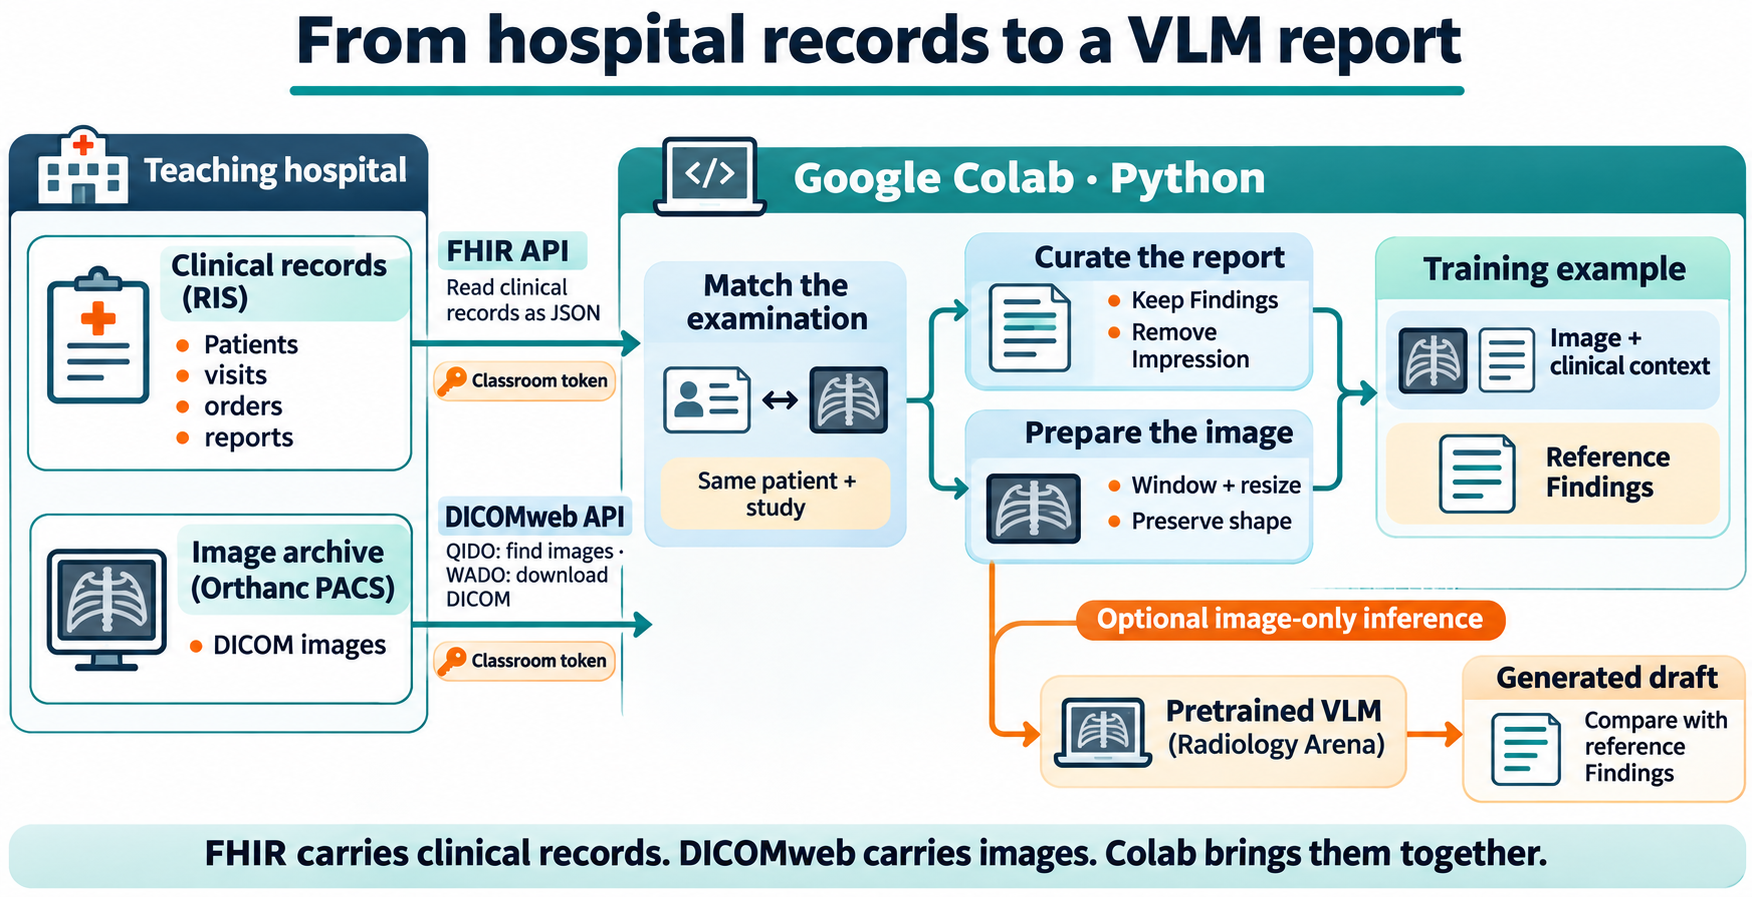

**The problem:** we want to train a vision-language model (VLM) to draft the **findings** of a chest X-ray report.
It receives an image plus the patient's age, recorded gender and reason for the visit. It should **not** generate an impression.

Today we prepare its training examples. We do not train the model yet.

| Model input | Training target |
|---|---|
| Chest X-ray + age at examination + administrative gender + visit reason | Findings text only |

We will walk through **one patient**, inspect each response, then repeat for a few cases.
Use a CPU runtime; you will not need to download a model.

*Dataset note: patient identities, clinical context and reports are invented for this exercise; image sources are attributed.
The small label-derived reports demonstrate a data workflow, not clinical model quality.*

## Getting started
**Wednesday, December 2, 2026 · 9:30–10:30 AM Central.**

Open a CPU runtime and run the cells in order, starting with the installation in section 2.
Have your classroom token ready for section 3. Run each collapsed helper cell once; you can expand it to read the code.

You will follow one examination from its clinical records to a complete image–text training example.
The hands-on exercises let you compare image resolutions and explore which examinations qualify for training.
Section 12 is optional and can also be completed after the session.

If a request fails or you need to catch up, the **recovery points** before sections 8 and 10 load a saved example.
The four-study exercise in section 12 requires a connection to the hospital.

For more practice after the lab, open the [complementary notebook](02_complementary.ipynb).
Hospital access is planned through **March 2, 2027**. Optional Arena inference depends on that service's availability and quota.

## 1. What is a FHIR connection?
FHIR (pronounced “fire”) is a standard way to exchange healthcare records. A **resource** is one record:
`Patient` stores demographics, `Encounter` stores a visit, and `DiagnosticReport` stores a report.

An **API** lets Python ask a server for information. An **endpoint** or **route** is its address.
Here, connecting just means sending an HTTP request to a known base URL. No database connection is needed.

```text
GET  https://hospital.example/fhir/R4/Patient?name=John
│    └──────── base URL ──────┘└── route ───┘└ filter ┘
└ read information
```

The response is **JSON**: named fields and values, which Python reads as dictionaries and lists.
A search returns a **Bundle**, a container with matching records. Reading `/Patient/pat-001` returns one record.

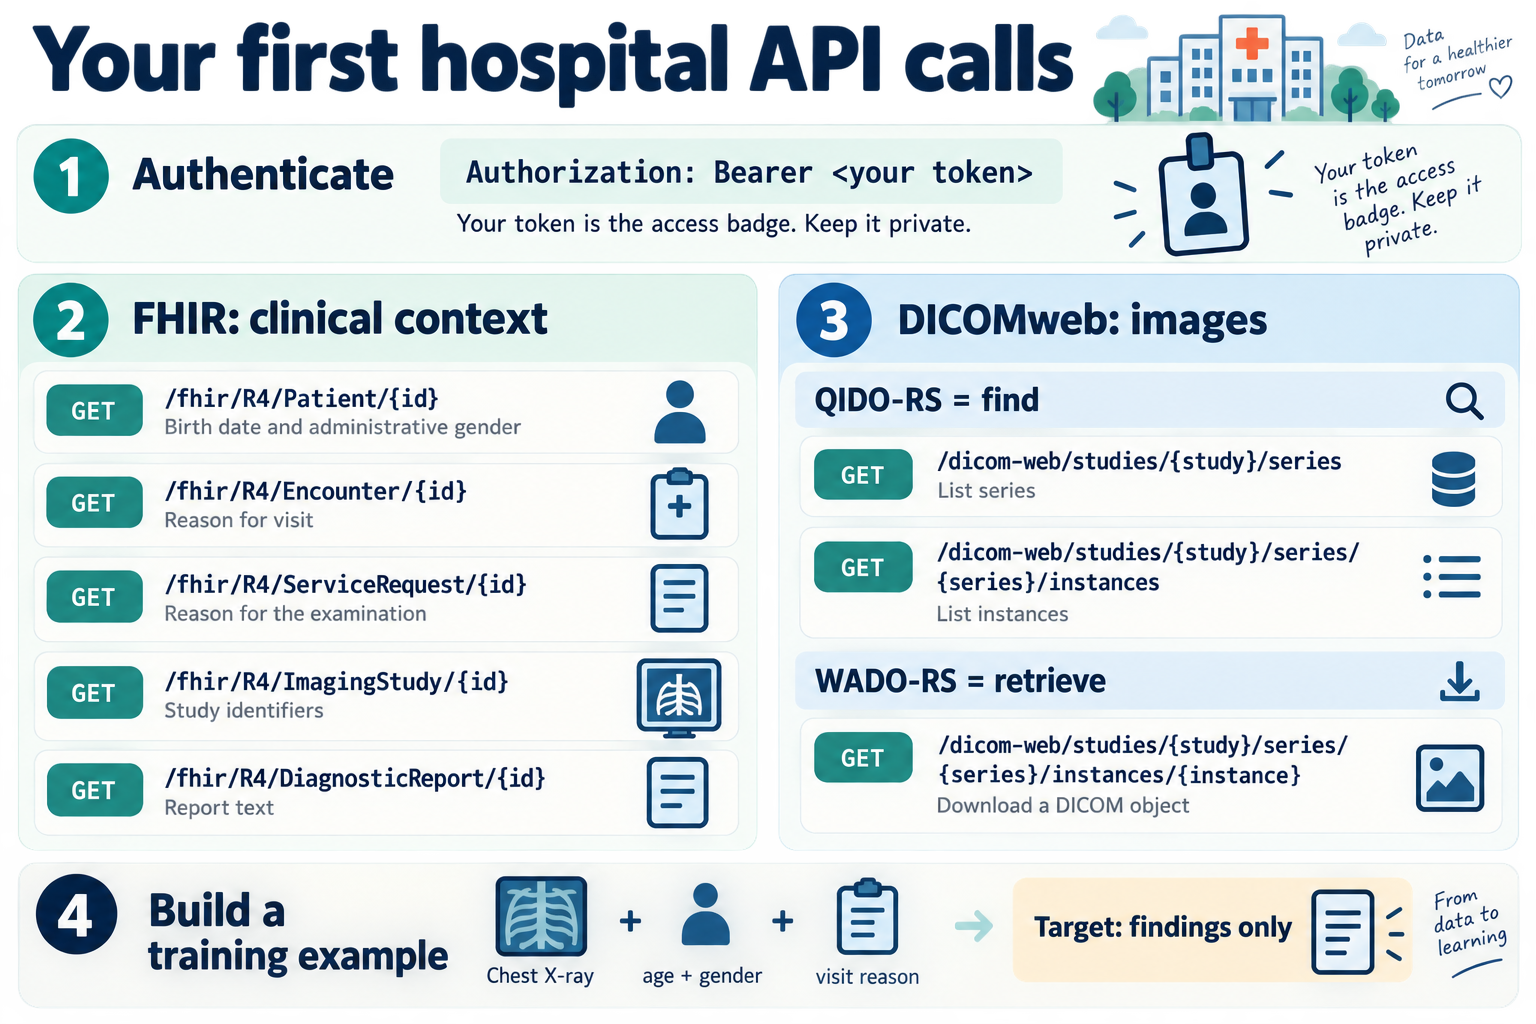

This route menu is a reading guide. The executable cells below are our “Try it out” buttons.

## 2. Install the teaching libraries
Run each cell from top to bottom with the ▶ button. `httpx` makes requests; `pydicom` opens DICOM files;
NumPy handles pixels; Pillow resizes images; pandas displays and compares report candidates.

In [ ]:
import os
import subprocess
import sys
if os.environ.get("RSNA_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                          "httpx==0.28.1", "pydicom==3.0.1", "numpy==2.2.5", "pillow==11.2.1", "pandas==2.2.3", "matplotlib==3.10.1"])

import base64
import getpass
import io
import json
import re
import html
import pandas as pd
from pathlib import Path
import httpx
import pydicom
from IPython.display import display
from PIL import Image

## 3. What is authentication?
The token is your classroom access badge. We send it in an HTTP **header**, not in the URL.
**Bearer** means the server accepts whoever presents that token. Keep it private.
Authentication checks the credential; authorization determines what it can access. Our token permits reading.

Enter the hospital URL and classroom token provided by your instructor. The password prompt hides the token.
Use the public hospital address: a Colab runtime cannot reach a server on your laptop's localhost.
Production hospitals often use OAuth/SMART login; here you will use an already-issued token.

In [ ]:
BASE_URL = os.environ.get("RSNA_BASE_URL", "https://rsnalearninglab.eduardofarina.com").rstrip("/")
TOKEN = os.environ.get("RSNA_TOKEN") or getpass.getpass("Classroom token: ")
client = httpx.Client(headers={"Authorization": f"Bearer {TOKEN}"}, timeout=120)

response = client.get(BASE_URL + "/fhir/R4/metadata")
print("HTTP status:", response.status_code)
response.raise_for_status()
print("FHIR version:", response.json()["fhirVersion"])

**200** means success. **401** means a missing, invalid, expired or revoked token.
**404** means the route or record was not found. **429** means slow down and retry later.
If connection fails, check that the hospital is running and the URL is reachable from your notebook.

From now on, this small helper repeats the request/error check. It also keeps the token on our hospital's origin.

In [ ]:
from urllib.parse import urljoin, urlparse

def get(path, **kwargs):
    url = urljoin(BASE_URL + "/", path)
    if urlparse(url)[:2] != urlparse(BASE_URL)[:2]:
        raise ValueError("Unexpected server address")
    response = client.get(url, **kwargs)
    response.raise_for_status()
    return response

## 4. Find a patient — your first search
`?name=John` is a search filter. Inspect the small part of the returned Bundle below.
The FHIR `id` is an API identifier; it is different from the hospital medical record number (MRN).

In [ ]:
bundle = get("/fhir/R4/Patient", params={"name": "John"}).json()
print("Matches:", bundle["total"])
patient = bundle["entry"][0]["resource"]
print(json.dumps({key: patient[key] for key in ["id", "name", "birthDate", "gender"]}, indent=2))
patient_id = patient["id"]

## 5. Which examination do we want?
Search `ImagingStudy` for this patient and modality `CR` (computed radiography).
`DX` is another radiograph modality; CT and MR are outside today's cohort.

We will use only **one page** in these first examples. The optional cohort step later follows all pages.
Choose a study ID from the displayed list.

In [ ]:
bundle = get("/fhir/R4/ImagingStudy", params={"patient": patient_id, "modality": "CR"}).json()
studies = [entry["resource"] for entry in bundle.get("entry", [])]
assert studies, "No CR studies found for this patient"
print([(study["id"], study["started"]) for study in studies])
study = studies[0]  # Change the index to explore another examination.

## 6. Follow the links: order → visit → patient context
A FHIR **reference** is a link such as `ServiceRequest/order-001`. Follow it to read that exact record.
`ServiceRequest.reasonCode` is the examination indication; `Encounter.reasonCode` is the visit reason.
They happen to match in our examples but can differ in a real hospital.

Age must be calculated **on the examination date**, not today. `Patient.gender` is administrative gender;
it is not a measurement of biological sex. Missing or unknown values remain unknown.

In [ ]:
order = get("/fhir/R4/" + study["basedOn"][0]["reference"]).json()
encounter = get("/fhir/R4/" + order["encounter"]["reference"]).json()
assert order["subject"] == encounter["subject"] == study["subject"]
print("Visit reason:", encounter["reasonCode"][0]["text"])
print("Exam indication:", order["reasonCode"][0]["text"])

In [ ]:
def age_at_study(birth_date, study_date):
    """Calculate completed years at acquisition, retaining missing/partial dates."""
    from datetime import date

    if not birth_date or len(birth_date) != 10:
        return None
    birth = date.fromisoformat(birth_date)
    acquired = date.fromisoformat(study_date[:10])
    if acquired < birth:
        raise ValueError("Study date precedes birth date")
    return acquired.year - birth.year - ((acquired.month, acquired.day) < (birth.month, birth.day))

context = {
    "age_years": age_at_study(patient.get("birthDate"), study["started"]),
    "administrative_gender": patient.get("gender", "unknown"),
    "reason_for_visit": encounter["reasonCode"][0]["text"],
}
print(context)

## 7. Match this examination to the correct report
Retrieve the candidate reports as FHIR `DiagnosticReport` resources for the patient selected above.
Several reports may belong to the same patient, so you need to identify the one for this examination.

**Predict first:** which report matches the accession and order? Could the same patient, encounter,
modality or a nearby report time lead you to the wrong report?

Compare accession and order identifiers, then inspect the encounter, modality and time difference.
Check the FHIR study reference and report status before accepting a match. Some examinations have
clinical records but no images available in this PACS.

In [ ]:
def fhir_report_rows(reports):
    """Translate standard FHIR fields to Imon's original exercise columns."""
    rows = []
    for report in reports:
        accession = next(
            (i["value"] for i in report.get("identifier", []) if i.get("system", "").endswith("/accession")),
            "",
        )
        modality = next(
            (
                c["code"]
                for cat in report.get("category", [])
                for c in cat.get("coding", [])
                if c.get("system") == "http://dicom.nema.org/resources/ontology/DCM"
            ),
            "",
        )
        rows.append(
            {
                "report_id": report["id"],
                "patient_id": report.get("subject", {}).get("reference", "").removeprefix("Patient/"),
                "accession_number": accession,
                "service_request_id": next(
                    (
                        r["reference"].removeprefix("ServiceRequest/")
                        for r in report.get("basedOn", [])
                        if r.get("reference", "").startswith("ServiceRequest/")
                    ),
                    "",
                ),
                "encounter_id": report.get("encounter", {}).get("reference", "").removeprefix("Encounter/"),
                "report_datetime": report.get("issued", report.get("effectiveDateTime")),
                "modality": modality,
                "exam_name": report.get("code", {}).get("text", ""),
                "report_text": base64.b64decode(report["presentedForm"][0]["data"]).decode(),
            }
        )
    return pd.DataFrame(
        rows,
        columns=[
            "report_id",
            "patient_id",
            "accession_number",
            "service_request_id",
            "encounter_id",
            "report_datetime",
            "modality",
            "exam_name",
            "report_text",
        ],
    )

def evaluate_report_matches(study, reports):
    """
    Compare candidate radiology reports against a selected ImagingStudy.
    """

    candidates = reports[reports["patient_id"] == study["patient_id"]].copy()

    # Convert times
    study_time = pd.to_datetime(study["study_datetime"], utc=True)

    candidates["report_datetime"] = pd.to_datetime(candidates["report_datetime"], errors="coerce", utc=True)

    # --------------------------------------------------------
    # Matching criteria
    # --------------------------------------------------------

    candidates["accession_match"] = candidates["accession_number"].fillna("").astype(str) == str(
        study["accession_number"]
    )

    candidates["order_match"] = candidates["service_request_id"].fillna("").astype(str) == str(
        study["service_request_id"]
    )

    candidates["encounter_match"] = candidates["encounter_id"].fillna("").astype(str) == str(
        study["encounter_id"]
    )

    candidates["modality_match"] = candidates["modality"].fillna("").astype(str) == str(study["modality"])

    # --------------------------------------------------------
    # Temporal distance
    # --------------------------------------------------------

    candidates["time_difference_hours"] = (
        candidates["report_datetime"] - study_time
    ).abs().dt.total_seconds() / 3600

    # --------------------------------------------------------
    # Define the high-confidence match
    # --------------------------------------------------------

    candidates["matched"] = (
        candidates["accession_match"]
        & bool(str(study["accession_number"] or "").strip())
        & bool(str(study["service_request_id"] or "").strip())
        & candidates["order_match"]
    )

    # Sort best candidates first
    candidates = candidates.sort_values(
        by=[
            "matched",
            "accession_match",
            "order_match",
            "encounter_match",
            "modality_match",
            "time_difference_hours",
        ],
        ascending=[False, False, False, False, False, True],
    )

    return candidates

def classify_match(row):
    if row["matched"]:
        return "MATCH"

    elif row["encounter_match"] and row["modality_match"]:
        return "POSSIBLE DISTRACTOR"

    else:
        return "NON-MATCH"

In [ ]:
# Fetch every page of candidate reports from the RIS via FHIR.
page = get("/fhir/R4/DiagnosticReport", params={"patient": patient_id, "_count": 100}).json()
reports = []
while True:
    reports.extend(entry["resource"] for entry in page.get("entry", []))
    next_url = next((link["url"] for link in page.get("link", []) if link["relation"] == "next"), None)
    if not next_url:
        break
    page = get(next_url).json()
selected_study = {
    "patient_id": patient_id,
    "study_uid": next(i["value"].removeprefix("urn:oid:") for i in study["identifier"] if i["system"] == "urn:dicom:uid"),
    "accession_number": next(i["value"] for i in order["identifier"] if i["system"].endswith("/accession")),
    "service_request_id": order["id"], "encounter_id": encounter["id"],
    "study_datetime": study["started"], "modality": study["modality"][0]["code"]}
candidate_reports = fhir_report_rows(reports)
print("Selected study:", selected_study)
display(candidate_reports[["report_id", "exam_name", "accession_number", "service_request_id"]])

**Completed solution — compare the identifiers before reading the report text.**

In [ ]:
match_results = evaluate_report_matches(selected_study, candidate_reports)
match_results["match_status"] = match_results.apply(classify_match, axis=1)
display_cols = ["report_id", "accession_match", "order_match", "encounter_match", "modality_match", "time_difference_hours", "match_status"]
display(match_results[display_cols])
matched_ids = set(match_results.loc[match_results["matched"], "report_id"])
matching = [r for r in reports if r["id"] in matched_ids
            and r["status"] in ("final", "amended", "corrected")
            and {"reference": "ImagingStudy/" + study["id"]} in r.get("imagingStudy", [])
            and {"reference": "ServiceRequest/" + order["id"]} in r.get("basedOn", [])]
assert matching, "No validated finalized match: skip and review this case"
latest = max(r["issued"] for r in matching)
matching = [r for r in matching if r["issued"] == latest]
assert len(matching) == 1, "Ambiguous finalized matches: review rather than selecting the first row"
report = matching[0]
assert report["subject"] == study["subject"]
report_text = base64.b64decode(report["presentedForm"][0]["data"]).decode("utf-8")
print("Validated report:", report["id"])
print(report_text)

### Recovery point 1 — rejoin at report processing
Only use this if you lost track during the FHIR steps, or the hospital is unavailable.
Run section 2 (imports) first. Then run the helper below, set the switch to
`True`, and continue at section 8. The original API calls remain above for you to revisit.
This restores the prepared patient, study, order, visit, context and report for **study-001**.

In [ ]:
#@title Recovery helper: one embedded teaching case (run once)
import gzip
_RECOVERY_PAYLOAD = '...'
def recovery_case():
    return json.loads(gzip.decompress(base64.b64decode(_RECOVERY_PAYLOAD)))


In [ ]:
USE_FHIR_RECOVERY = False
if USE_FHIR_RECOVERY:
    saved = recovery_case()
    patient, study, order, encounter, report = [saved[key] for key in ["patient", "study", "order", "encounter", "report"]]
    patient_id = patient["id"]
    context = saved["context"]
    report_text = base64.b64decode(report["presentedForm"][0]["data"]).decode()
    print("Restored study-001. Continue at section 8.")

## 8. Keep findings; remove the impression
Our **target** is only the findings section. We remove the report header, patient identifiers and impression
by selecting text **between section headings**. We do not remove words such as “no” or “possible”.

This simple rule is appropriate for our known report template. Unlabeled reports need review.
The section extractor retains organ subheadings inside Findings; whitespace cleanup preserves negation and uncertainty.
No language model is needed for this transformation. The impression and report text must never be part of the model input.

In [ ]:
def findings_only(text):
    """Extract the labeled findings section; reject unlabeled reports for review."""
    match = re.search(
        r"(?ims)^\s*findings(?:\s*\(preliminary\))?\s*:\s*(.*?)"
        r"(?=^\s*(?:impression|conclusion|recommendations|addendum)\s*:|\Z)",
        text,
    )
    if not match or not match.group(1).strip():
        raise ValueError("No labeled findings section; review this report manually")
    return " ".join(match.group(1).split())

def extract_report_section(text, section="FINDINGS"):
    """Imon's section extraction, retaining organ subheadings within Findings."""
    if text is None or pd.isna(text):
        return None
    headings = r"EXAM|CLINICAL HISTORY|HISTORY|COMPARISON|TECHNIQUE|FINDINGS|IMPRESSION|CONCLUSION|RECOMMENDATIONS|ADDENDUM|BREAST COMPOSITION|BI-RADS"
    # Require a colon or newline on terminating headings, while permitting inline headings.
    pattern = (
        rf"(?:^|\n)[ \t]*{re.escape(section)}(?:[ \t]*\(preliminary\))?[ \t]*(?::|\n)[ \t\r\n]*"
        rf"(.*?)(?=\n[ \t]*(?:{headings})[ \t]*(?::|\n)|\Z)"
    )
    match = re.search(pattern, str(text), flags=re.IGNORECASE | re.DOTALL)
    return match.group(1).strip() if match else None

def clean_report_text(text):
    if text is None or pd.isna(text):
        return None
    text = html.unescape(str(text)).replace("\xa0", " ")
    return re.sub(r"\s+", " ", text).strip()

sections = {name: extract_report_section(report_text, name)
            for name in ["CLINICAL HISTORY", "COMPARISON", "TECHNIQUE", "FINDINGS", "IMPRESSION"]}
target = clean_report_text(sections["FINDINGS"])
assert target, "Missing findings: review this report"
assert target == findings_only(report_text), "Review extraction differences"
print("Model target:", target)

### Compare report structures: CXR → CT → mammography
Retrieve these three report examples from the RIS. Predict which headings are **major sections**
and which belong **inside Findings**, then compare the source and extracted text below.

- **CXR (RPT-2006):** a short narrative, including uncertainty ("favored to represent").
- **CT (RPT-2001):** retain LUNGS AND AIRWAYS, PLEURA, MEDIASTINUM, HEART and UPPER ABDOMEN inside Findings.
- **Mammography (RPT-2004):** retain RIGHT BREAST and LEFT BREAST inside Findings; extract BREAST COMPOSITION,
  IMPRESSION and BI-RADS separately. Recommendations in Impression stay outside the Findings target.

These are **text-only extraction examples**, not additional image–report training pairs. We have no mammograms
in this PACS, and these original CT/CXR reports are not paired to our teaching images. A missing section remains
missing, not an invented normal result. Compare the original paragraphs before accepting any extraction.
Next, return to the matched CXR (`study-001`) and retrieve its image.

In [ ]:
def modality_extraction_examples(reports):
    """Use three unchanged Imon reports for text-only comparison, never image pairing."""
    examples = []
    for modality, source_id in (("CXR", "RPT-2006"), ("CT", "RPT-2001"), ("Mammography", "RPT-2004")):
        matches = [
            r
            for r in reports
            if any(
                i.get("system", "").endswith("/ris-source-report") and i.get("value") == source_id
                for i in r.get("identifier", [])
            )
        ]
        if len(matches) != 1:
            raise ValueError(f"Expected one original RIS report for {source_id}; review available records")
        resource = matches[0]
        text = base64.b64decode(resource["presentedForm"][0]["data"]).decode()
        examples.append(
            {
                "modality": modality,
                "source_report_id": source_id,
                "fhir_report_id": resource["id"],
                "original_report": text,
                "findings": clean_report_text(extract_report_section(text, "FINDINGS")),
                "impression": clean_report_text(extract_report_section(text, "IMPRESSION")),
                "breast_composition": clean_report_text(extract_report_section(text, "BREAST COMPOSITION")),
                "bi_rads": clean_report_text(extract_report_section(text, "BI-RADS")),
            }
        )
    return examples

if globals().get("USE_FHIR_RECOVERY", False):
    print("Text comparison needs the live RIS. Continue with the recovered CXR target below.")
else:
    extraction_examples = modality_extraction_examples(reports)
    for example in extraction_examples:
        print("\n---", example["modality"], example["source_report_id"], "(text only) ---")
        print(example["original_report"])
        display(pd.DataFrame([
            {"section": key, "extracted_text": example[key]}
            for key in ["findings", "impression", "breast_composition", "bi_rads"]
        ]))
    print("Compared original RIS reports: CXR, CT, Mammography")
    assert target == clean_report_text(extract_report_section(report_text, "FINDINGS"))
    print("Continue with the matched CXR:", study["id"], report["id"])

## 9. From FHIR to DICOMweb
FHIR gives us clinical context and imaging identifiers. **DICOMweb** lets us query and retrieve images from the PACS.
A study contains series; a series contains instances (DICOM objects).

| Call | Purpose | Response |
|---|---|---|
| QIDO-RS: `GET /dicom-web/studies/{study}/series` | Find series | DICOM JSON |
| QIDO-RS: `GET /dicom-web/studies/{study}/series/{series}/instances` | Find instances | DICOM JSON |
| WADO-RS: same path + `/{instance}` | Retrieve one object | DICOM bytes inside a multipart response |

FHIR resource IDs and DICOM UIDs are different. First read the Study Instance UID from FHIR.
DICOM JSON uses tag numbers: `0020000E` = Series Instance UID; `00080018` = SOP Instance UID.

In [ ]:
study_uid = next(item["value"].removeprefix("urn:oid:") for item in study["identifier"]
                 if item["system"] == "urn:dicom:uid")
series_path = f"/dicom-web/studies/{study_uid}/series"
series_list = get(series_path, headers={"Accept": "application/dicom+json"}).json()
print("Series found:", len(series_list))
series_uid = series_list[0]["0020000E"]["Value"][0]
instances_path = f"{series_path}/{series_uid}/instances"
instances = get(instances_path, headers={"Accept": "application/dicom+json"}).json()
instance_uid = instances[0]["00080018"]["Value"][0]
print("Instances in this series:", len(instances))

Our curated CXR cases have one series and one image. Selecting the first item is specific to this pack;
a general dataset needs explicit view, series and frame selection.

The server wraps the DICOM file in a **multipart envelope**, like an attachment to a message.
Run the helper below to extract the DICOM file from that envelope.

In [ ]:
#@title Helper: open the DICOM response envelope (run once)
from email.parser import BytesParser
from email.policy import default

def read_dicom(response):
    content_type = response.headers.get("content-type", "")
    if content_type.startswith("multipart/"):
        envelope = BytesParser(policy=default).parsebytes(
            ("Content-Type: " + content_type + "\r\nMIME-Version: 1.0\r\n\r\n").encode()
            + response.content)
        parts = [p.get_payload(decode=True) for p in envelope.iter_parts()
                 if p.get_content_type() == "application/dicom"]
        if len(parts) != 1:
            raise ValueError("Expected one DICOM attachment")
        data = parts[0]
    else:
        data = response.content
    return pydicom.dcmread(io.BytesIO(data))

In [ ]:
response = get(f"{instances_path}/{instance_uid}",
               headers={"Accept": 'multipart/related; type="application/dicom"; transfer-syntax=*'})
ds = read_dicom(response)
assert str(ds.PatientID) == patient["identifier"][0]["value"]
assert str(ds.AccessionNumber) == selected_study["accession_number"]
assert str(ds.StudyInstanceUID) == study_uid
assert str(ds.SeriesInstanceUID) == series_uid
assert str(ds.SOPInstanceUID) == instance_uid
print("Pixel array:", ds.pixel_array.shape)
print("Photometric interpretation:", ds.PhotometricInterpretation)
print("Window center / width:", ds.get("WindowCenter", "not supplied"), ds.get("WindowWidth", "not supplied"))

### Recovery point 2 — rejoin at image processing
If DICOMweb retrieval failed, run the recovery helper above and set this switch to `True`.
It opens the embedded DICOM for **study-001**. Use recovery point 1 as well if your current case differs;
the assertion prevents pairing this image with another patient's report. Continue at section 10.
You can skip the network cells in section 9 when using this recovery point.

In [ ]:
USE_DICOM_RECOVERY = False
if USE_DICOM_RECOVERY:
    saved = recovery_case()
    assert study["id"] == saved["study"]["id"], "Use recovery point 1 first to restore the matching case"
    ds = pydicom.dcmread(io.BytesIO(base64.b64decode(saved["dicom_base64"])))
    study_uid = str(ds.StudyInstanceUID)
    print("Prepared DICOM loaded. Continue at section 10.")

## 10. Turn DICOM pixels into a model-ready image
A DICOM file contains metadata and pixels. Its pixel values are not always display-ready.

1. Decode the pixels and apply the modality LUT/rescale, if present.
2. Apply the stored VOI LUT/window. Without one, use a percentile contrast range for this demonstration.
3. Handle `MONOCHROME1` inversion and set padding pixels to black.
4. Convert to 8-bit grayscale and resize the **longest side to at most 896 pixels**, without upscaling.

**Windowing** maps a chosen intensity range to black–white. A narrower range increases contrast but clips more values.
Use the radiograph's own settings; do not apply a CT lung window to a chest radiograph.

**896 is a teaching budget, not a universal VLM limit.** Resizing preserves aspect ratio (with integer rounding),
but reduces detail. A 2048 × 1536 image becomes 896 × 672. The chosen model's processor may resize or crop again.
Run the helper below to apply these steps to the retrieved radiograph.

In [ ]:
#@title Helper: prepare a grayscale radiograph (run once; expand to inspect)
def prepare_cxr(ds, max_side=896, window=None):
    """Single-frame grayscale teaching pipeline; window=(center,width) is optional."""
    import numpy as np
    from PIL import Image
    from pydicom.pixels import apply_modality_lut, apply_voi_lut

    if max_side < 1:
        raise ValueError("max_side must be positive")
    raw = ds.pixel_array
    if raw.ndim != 2 or ds.PhotometricInterpretation not in ("MONOCHROME1", "MONOCHROME2"):
        raise ValueError("This exercise expects a single-frame grayscale radiograph")
    valid = np.isfinite(raw)
    if "PixelPaddingValue" in ds:
        low = float(ds.PixelPaddingValue)
        high = float(ds.get("PixelPaddingRangeLimit", low))
        valid &= (raw < min(low, high)) | (raw > max(low, high))
    pixels = apply_modality_lut(raw, ds).astype(float)
    valid &= np.isfinite(pixels)
    if not valid.any():
        raise ValueError("No usable pixels")
    if window is not None:
        center, width = window
        if not np.isfinite([center, width]).all() or width <= 0:
            raise ValueError("Window width must be positive and values finite")
        # Explicit linear teaching window, distinct from DICOM's LINEAR formula.
        low, high = center - width / 2, center + width / 2
        method = "manual linear window"
    elif "VOILUTSequence" in ds or ("WindowCenter" in ds and "WindowWidth" in ds):
        pixels = apply_voi_lut(pixels, ds).astype(float)
        if "VOILUTSequence" in ds:
            low, high = 0, 2 ** int(ds.VOILUTSequence[0].LUTDescriptor[2]) - 1
        else:
            # pydicom windowing output spans the modality-transformed bit range.
            bits = int(ds.BitsStored)
            low, high = (
                (0, 2**bits - 1) if ds.PixelRepresentation == 0 else (-(2 ** (bits - 1)), 2 ** (bits - 1) - 1)
            )
            if "ModalityLUTSequence" in ds:
                low, high = 0, 2 ** int(ds.ModalityLUTSequence[0].LUTDescriptor[2]) - 1
            else:
                slope, intercept = float(ds.get("RescaleSlope", 1)), float(ds.get("RescaleIntercept", 0))
                low, high = sorted((low * slope + intercept, high * slope + intercept))
        method = "DICOM VOI LUT/window (first preset)"
    else:
        low, high = np.percentile(pixels[valid], [0.5, 99.5])
        method = "0.5–99.5 percentile fallback"
    pixels = np.clip((pixels - low) / max(float(high - low), 1e-8), 0, 1)
    if ds.PhotometricInterpretation == "MONOCHROME1":
        pixels = 1 - pixels
    pixels[~valid] = 0
    image = Image.fromarray(np.rint(pixels * 255).astype("uint8"))
    original_size = image.size
    image.thumbnail((max_side, max_side), Image.Resampling.LANCZOS)
    return image, {
        "original_size": original_size,
        "output_size": image.size,
        "intensity_method": method,
        "max_side": max_side,
    }

In [ ]:
MAX_SIDE = 896
image, preprocessing = prepare_cxr(ds, max_side=MAX_SIDE)
print(preprocessing)
display(image)

### Hands-on 1 — how much detail survives resizing?
Compare the full-resolution display image with the resized version. Both use the same intensity transforms;
"original" here means original dimensions, not raw DICOM values. Change `RESIZE_SIDE` to 448, 224 or 112 and
rerun the next cell. What becomes harder to see? The exported training image keeps its 896-pixel cap.
Run the cell, then change the resolution and compare the images.

In [ ]:
import matplotlib.pyplot as plt
RESIZE_SIDE = 896  # Try 448, 224 or 112.
original_display, _ = prepare_cxr(ds, max_side=max(ds.Rows, ds.Columns))
resized_display, _ = prepare_cxr(ds, max_side=RESIZE_SIDE)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, preview, label in zip(axes, [original_display, resized_display], ["Original dimensions", "Resized"]):
    ax.imshow(preview, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(f"{label}: {preview.width} × {preview.height}")
    ax.axis("off")
plt.tight_layout()
plt.show()
plt.close(fig)

## 11. Assemble one training example
The model input is the processed image (referenced by `image_path`) and a text prompt containing
instructions and clinical context. Findings are the reference text the model should learn to generate.
We keep IDs for tracing and patient-level splitting, but exclude them from the prompt.

In [ ]:
def make_prompt(context):
    age = context["age_years"] if context["age_years"] is not None else "unknown"
    return ("Draft the findings section of this chest X-ray report. Do not include an impression.\n"
            f"Age at examination: {age} years.\n"
            f"Administrative gender: {context['administrative_gender']}.\n"
            f"Reason for visit: {context['reason_for_visit']}.")

output_dir = Path("cxr-training")
output_dir.mkdir(exist_ok=True)
image_path = output_dir / f"{study['id']}.png"
image.save(image_path)
record = {"patient_id": patient_id, "study_id": study["id"], "report_id": report["id"],
          "study_uid": study_uid, "accession_number": order["identifier"][0]["value"],
          "service_request_id": order["id"], "encounter_id": encounter["id"],
          "match_method": "accession+order+FHIR study",
          "match_status": "RECOVERY" if globals().get("USE_FHIR_RECOVERY", False) else "HIGH_CONFIDENCE",
          "image_path": str(image_path), "context": context,
          "prompt": make_prompt(context), "target": target, "preprocessing": preprocessing}
Path("image-report-pair.json").write_text(json.dumps(record, indent=2))
print("IMAGE:")
with Image.open(record["image_path"]) as saved_image:
    display(saved_image.copy())
print("INPUT:\n" + record["prompt"])
print("\nTARGET:\n" + record["target"])

## 12. Automating the workflow: from one example to a small dataset
The helper automates sections 4–11: clinical context, report matching, DICOM retrieval and preprocessing.
It follows every search page and checks the image identifiers against the selected patient and examination.
A radiograph without suitable reference Findings cannot form a complete supervised training example.

We will retrieve four studies once and export only eligible pairs. Predict which report is selected for
**study-002** (preliminary and corrected reports), and what happens to **study-004** (no report).
You can complete this optional section now or return to it after the lab.

In [ ]:
#@title Helper: repeat the same workflow for selected studies

def search_all(resource, **params):
    page = get("/fhir/R4/" + resource, params=params).json()
    records = []
    while True:
        records.extend(entry["resource"] for entry in page.get("entry", []))
        next_url = next((link["url"] for link in page.get("link", []) if link["relation"] == "next"), None)
        if not next_url:
            return records
        page = get(next_url).json()


def build_case(study_id, allow_unreported=False):
    study = get("/fhir/R4/ImagingStudy/" + study_id).json()
    if not any(m["code"] in ("CR", "DX") for m in study["modality"]):
        raise ValueError("Not a chest radiograph case in this pack")
    patient = get("/fhir/R4/" + study["subject"]["reference"]).json()
    order_ref = study["basedOn"][0]["reference"]
    order = get("/fhir/R4/" + order_ref).json()
    encounter = get("/fhir/R4/" + order["encounter"]["reference"]).json()
    assert order["subject"] == encounter["subject"] == study["subject"]
    reports = search_all("DiagnosticReport", patient=patient["id"])
    reports = [r for r in reports if r["status"] in ("final", "corrected", "amended")
               and {"reference": "ImagingStudy/" + study_id} in r.get("imagingStudy", [])
               and {"reference": order_ref} in r.get("basedOn", [])
               and r["subject"] == study["subject"]]
    if not reports and not allow_unreported:
        raise ValueError("No finalized report")
    reports.sort(key=lambda r: r["issued"], reverse=True)
    if len(reports) > 1 and reports[0]["issued"] == reports[1]["issued"]:
        raise ValueError("Ambiguous latest reports: review before pairing")
    report = reports[0] if reports else None
    target = findings_only(base64.b64decode(report["presentedForm"][0]["data"]).decode()) if report else None
    context = {"age_years": age_at_study(patient.get("birthDate"), study["started"]),
               "administrative_gender": patient.get("gender", "unknown"),
               "reason_for_visit": next((r["text"] for r in encounter.get("reasonCode", []) if r.get("text")), "unknown")}
    uid = next(i["value"].removeprefix("urn:oid:") for i in study["identifier"] if i["system"] == "urn:dicom:uid")
    series = get(f"/dicom-web/studies/{uid}/series", headers={"Accept": "application/dicom+json"}).json()
    assert len(series) == 1, "Review series selection"
    series_uid = series[0]["0020000E"]["Value"][0]
    path = f"/dicom-web/studies/{uid}/series/{series_uid}/instances"
    instances = get(path, headers={"Accept": "application/dicom+json"}).json()
    assert len(instances) == 1, "Review instance selection"
    instance_uid = instances[0]["00080018"]["Value"][0]
    ds = read_dicom(get(path + "/" + instance_uid, headers={"Accept": 'multipart/related; type="application/dicom"; transfer-syntax=*'}))
    assert str(ds.StudyInstanceUID) == uid and str(ds.SeriesInstanceUID) == series_uid
    assert str(ds.SOPInstanceUID) == instance_uid
    assert str(ds.PatientID) in {item["value"] for item in patient.get("identifier", [])}
    assert str(ds.AccessionNumber) in {item["value"] for item in order.get("identifier", [])}
    image, preprocessing = prepare_cxr(ds, max_side=MAX_SIDE)
    path = output_dir / f"{study_id}.png"
    image.save(path)
    return {"patient_id": patient["id"], "study_id": study_id, "report_id": report["id"] if report else None,
            "study_uid": uid, "accession_number": order["identifier"][0]["value"],
            "service_request_id": order["id"], "encounter_id": encounter["id"],
            "match_method": "FHIR study+order", "match_status": "HIGH_CONFIDENCE" if report else "NO_REPORT",
            "image_path": str(path), "context": context, "prompt": make_prompt(context),
            "target": target, "preprocessing": preprocessing}

**Completed solution — prepare the cohort once.** The next exercise only changes its display.

In [ ]:
SELECTED_STUDIES = ["study-001", "study-002", "study-003", "study-004"]
records, skipped, all_cases = [], [], []
for study_id in SELECTED_STUDIES:
    try:
        case = build_case(study_id, allow_unreported=True)
        all_cases.append(case)
        if case["target"]:
            records.append(case)
        else:
            skipped.append({"study_id": study_id, "reason": "No finalized report"})
    except ValueError as error:
        skipped.append({"study_id": study_id, "reason": str(error)})
Path("cxr-training.jsonl").write_text("".join(json.dumps(row) + "\n" for row in records))
print("Training examples:", len(records))
print("Skipped:", skipped)

### Hands-on 2 — which radiographs make it into the training set?
Run the completed example with `VIEW = "all"` to see all four radiographs and available Findings.
Predict which will be included, then change `VIEW` to `"training"` and rerun **only this display cell**.
It uses cached files: it neither downloads images again nor changes the exported dataset.
A missing report excludes a case from supervised training, but it may still be an inference candidate.

In [ ]:
VIEW = "all"  # Change to "training" to check your prediction.
if VIEW not in {"all", "training"}:
    raise ValueError('Choose VIEW = "all" or "training"')
visible_cases = all_cases if VIEW == "all" else records
print(f"Showing {len(visible_cases)} radiographs; {len(records)} eligible training examples.")
if visible_cases:
    fig, axes = plt.subplots(1, len(visible_cases), figsize=(4 * len(visible_cases), 4), squeeze=False)
    for ax, case in zip(axes[0], visible_cases):
        with Image.open(case["image_path"]) as preview:
            ax.imshow(preview, cmap="gray", vmin=0, vmax=255)
        ax.set_title(case["study_id"] + (" — training" if case["target"] else " — no report"))
        ax.axis("off")
        print(case["study_id"], "FINDINGS:", case["target"] or "No finalized report; excluded from training.")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

## Take-Home Messages & Homework
1. **Match the patient and examination carefully.** Clinical context, image and report must refer to the same case.
2. **Templates vary.** CXR, CT and mammography need different section boundaries; preserve negation and uncertainty.
3. **Separate input and target.** The image and clinical context are inputs; corresponding Findings are the reference target.
4. **Quality matters.** Not every available image has an appropriate report for supervised training.
5. **Preprocessing changes what the model sees.** Windowing and resizing can remove visible detail.

### Explore the complementary notebook
Open [02_complementary.ipynb](02_complementary.ipynb) for optional independent practice:
- **A:** resolution and windowing experiments;
- **B:** duplicate images and patient-level splits;
- **13:** the image–text data loader;
- **14–16:** unread examinations, optional Arena inference and scheduler/listener workflows.

### Practical information
Use the same hospital URL and your assigned classroom token. Planned hospital access continues through
**March 2, 2027**. The basic exercises run on CPU; Arena is external, quota-dependent and disabled by default.
No homework is graded. Bring questions to the faculty during the session, or open an issue in the
[RSNA repository](https://github.com/RSNA/AI-Deep-Learning-Lab-2026/issues) mentioning Lab 08.
Never include classroom tokens or patient data in a public issue.

You have prepared an image, clinical context and Findings target for supervised training.

In [ ]:
client.close()

## One last step — let a VLM draft Findings
You have prepared data that a model can use. Now try the processed image from your first case with a
**pretrained MedGemma model** hosted through Radiology Arena. We have not trained this model in the lab.

Set `RUN_FINAL_INFERENCE = True` and run the cell below. It sends only the prepared PNG; your hospital token,
patient identifiers, reference Findings and clinical context stay in this notebook. This endpoint uses a fixed
Findings prompt and accepts **images only**. A model that uses your age, gender and visit reason needs a
context-aware endpoint. No Colab GPU is needed because inference runs on the remote service.

Compare the generated draft with the reference Findings. Which statements agree? What did the model add or miss?
Our short teaching reference is not a complete clinical gold standard, so this comparison is not an accuracy score.
The generated draft needs human review and is not written back to the hospital.

The call is optional and disabled during Run all. A busy or unavailable backend may return an error.
This cell remembers an attempted call to avoid submitting it again accidentally; restart the runtime for a new attempt.

In [ ]:
RUN_FINAL_INFERENCE = False  # Set True to try one image.
FINAL_MODEL = "medgemma-1.5-4b"

if not RUN_FINAL_INFERENCE:
    print("Optional: set RUN_FINAL_INFERENCE = True to generate Findings for your prepared image.")
elif globals().get("final_inference_attempted", False):
    print("This runtime already attempted the demo; the previous result is shown above.")
else:
    final_inference_attempted = True
    try:
        if os.environ.get("RSNA_SKIP_INSTALL") != "1":
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gradio-client==2.4.0"])
        import uuid
        from gradio_client import Client, handle_file

        arena = Client("eduardofarina/radiology-arena", verbose=False, httpx_kwargs={"timeout": 120})
        job = arena.submit(image=handle_file(record["image_path"]), model_id=FINAL_MODEL,
                           selected_prompt_policy="canonical", browser_token=str(uuid.uuid4()),
                           api_name="/generate_single")
        response = job.result(timeout=180)
        if not isinstance(response, (list, tuple)) or len(response) != 2 or not isinstance(response[0], str):
            raise ValueError("Unexpected Arena response; no draft accepted")
        answer = response[0]
        marker = "\n\n---\n\n**Prompt source:**"
        if "### Could not generate" in answer or "[Interface preview" in answer:
            raise ValueError(answer[:500])
        if not answer.startswith("### ") or marker not in answer or "\n\n" not in answer.split(marker)[0]:
            raise ValueError("Unexpected Arena format; no draft accepted")
        generated_findings = html.unescape(answer.split(marker, 1)[0].split("\n\n", 1)[1]).strip()
        if not generated_findings:
            raise ValueError("Arena returned an empty draft")
        print("MODEL:", FINAL_MODEL, "— pretrained, image-only inference")
        display(pd.DataFrame({"Reference Findings": [record["target"]], "Generated draft": [generated_findings]}))
    except Exception as error:
        print("No model draft was generated. Your prepared training example is still available.")
        print(type(error).__name__ + ": " + str(error)[:600])